In [200]:
# Solve a real world problem.
# To identify handwritten digets by a model.

# Step 1: Get all the handwritte digits data samples from mnist_train generalized from 0 to 9

# Step 2: Get the mnist_test data sample, and run them onto the model to identify the handwritten digits

In [201]:
import csv
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from IPython.display import clear_output, display
import time
import copy
from timeit import default_timer as timer

In [202]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [203]:
path = "/content/drive/MyDrive/Data/"
start_time = timer()
numbers = pd.read_csv(path + "mnist_train.csv")
print("Total time to read the ground truth data:", timer() - start_time, 'secs')

Total time to read the ground truth data: 3.5476653030000307 secs


In [204]:
num_0 = None
num_1 = None
num_2 = None
num_3 = None
num_4 = None
num_5 = None
num_6 = None
num_7 = None
num_8 = None
num_9 = None

printstatment = False

In [ ]:
# New: from ch 2 (will be used for step 2)
def comparing_pixel_points (num, x,y,u,v):
  ct = 0
  for i in range (len(y)):
    yaxis = y[i]
    xaxis = x[i]

    for j in range(len(v)):
      vaxis = v[j]
      uaxis = u[j]

      if ((yaxis == vaxis) and (xaxis == uaxis)):
        ct += 1
  print('Number of matches for the number', num, 'is:', ct, '& probability density is', round((ct/len(y))*100), '%')
  return ct

In [205]:
def generalizeNum(num, pix_val_num):
  t1 = pix_val_num
  t1 = np.array(t1)
  if num is None:
    num = t1
  else:
    num = num + t1
  return num

In [206]:
def outPrint(statment):
  global printstatment
  if printstatment:
    print(statment)

In [207]:
def numNormalization(normalize):
  n_max = float(normalize.max())
  normalize = normalize/n_max
  normreshape = normalize.reshape(28,28)
  return normreshape

In [208]:
def stackNum(num, pix_val_num):
  global num_0
  global num_1
  global num_2
  global num_3
  global num_4
  global num_5
  global num_6
  global num_7
  global num_8
  global num_9

  if num == 0:
    outPrint("The label defined for the number is 0")
    num_0 = generalizeNum(num_0, pix_val_num)

  elif num == 1:
    outPrint("The label defined for the number is 1")
    num_1 = generalizeNum(num_1, pix_val_num)

  elif num == 2:
    outPrint("The label defined for the number is 2")
    num_2 = generalizeNum(num_2, pix_val_num)

  elif num == 3:
    outPrint("The label defined for the number is 3")
    num_3 = generalizeNum(num_3, pix_val_num)

  elif num == 4:
    outPrint("The label defined for the number is 4")
    num_4 = generalizeNum(num_4, pix_val_num)

  elif num == 5:
    outPrint("The label defined for the number is 5")
    num_5 = generalizeNum(num_5, pix_val_num)

  elif num == 6:
    outPrint("The label defined for the number is 6")
    num_6 = generalizeNum(num_6, pix_val_num)

  elif num == 7:
    outPrint("The label defined for the number is 7")
    num_7 = generalizeNum(num_7, pix_val_num)

  elif num == 8:
    outPrint("The label defined for the number is 8")
    num_8 = generalizeNum(num_8, pix_val_num)

  elif num == 9:
    outPrint("The label defined for the number is 9")
    num_9 = generalizeNum(num_9, pix_val_num)


In [209]:
start_time_2 = timer()
for i in range (len(numbers)):
  num = numbers.iloc[i,0] # ground truth number or sample of handwritten digits
  pix_val_num = numbers.iloc[i,1:] # gray scale pixel values of the ground truth number or sample

  stackNum(num, pix_val_num)
  #if i == 10:
   # break

print("Total time to process and generalize the ground truth data:", timer() - start_time_2, 'secs')


Total time to process and generalize the ground truth data: 13.283489325999653 secs


In [210]:
num_0_norm = numNormalization(num_0)
num_1_norm = numNormalization(num_1)
num_2_norm = numNormalization(num_2)
num_3_norm = numNormalization(num_3)
num_4_norm = numNormalization(num_4)
num_5_norm = numNormalization(num_5)
num_6_norm = numNormalization(num_6)
num_7_norm = numNormalization(num_7)
num_8_norm = numNormalization(num_8)
num_9_norm = numNormalization(num_9)


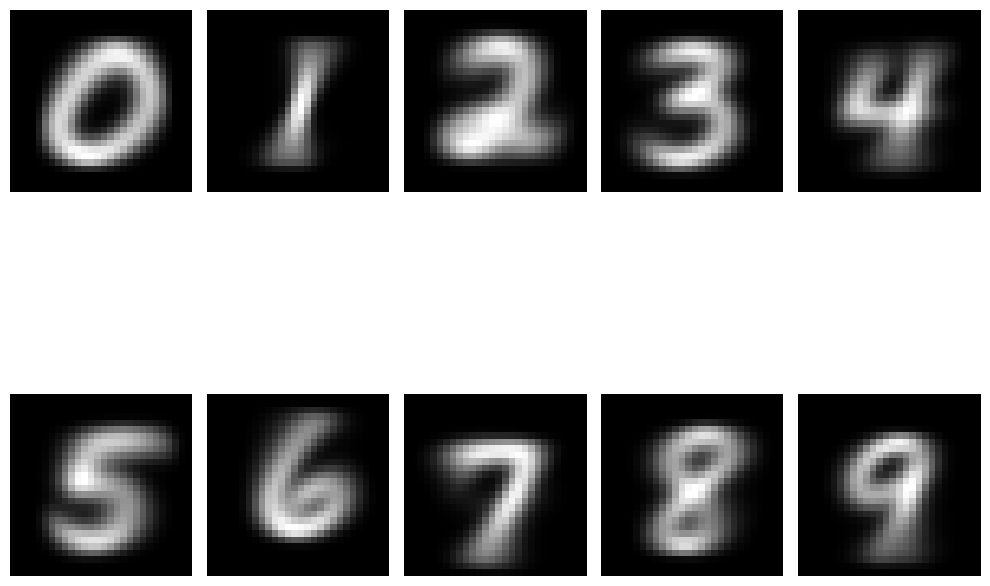

In [211]:
fig = plt.figure(figsize = (10,10))
columns = 5
rows = 2
images = [num_0_norm,
          num_1_norm,
          num_2_norm,
          num_3_norm,
          num_4_norm,
          num_5_norm,
          num_6_norm,
          num_7_norm,
          num_8_norm,
          num_9_norm]

for i in range(0, (columns * rows)):
  img = images[i]
  fig.add_subplot(rows, columns, i+1)
  plt.axis('off')
  plt.imshow(img, cmap ='gray')
plt.tight_layout()
plt.show()